# 02 · Features

A **feature** is one piece of information the model is allowed to look at when it predicts whether a flight will arrive late.

**The rule for this project:** a feature may only use what is known *before the flight leaves*. Anything that happens on the day (actual departure time, taxi time, the delay itself) is off limits. Breaking this rule is called **leakage**: the model looks great on paper and is useless in real life.

`src/features.py` builds the features from the schedule. This notebook shows what they are, checks them, and looks at whether they are related to late arrivals.

| Group | Features | Idea |
|---|---|---|
| Time | hour, weekday, month, day of month, days from a federal holiday | Delays follow the clock and the calendar |
| Flight | airline, origin, destination, distance, scheduled flight time | Some airlines, airports and routes run later than others |
| Crowding | flights scheduled at the origin and destination in the same hour | Busy airports have less room to recover |
| Aircraft rotation | leg number that day, legs planned that day, turnaround time, where the plane comes from, hours in service | A plane that falls behind stays behind |
| Aircraft | model family and age, from the FAA aircraft registry | Fleets differ in how they are used and maintained |

## 1. Load the feature table

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import PercentFormatter

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "load.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import plotstyle as ps
from features import CATEGORICAL_FEATURES, FEATURE_COLUMNS, NUMERIC_FEATURES, TARGET, load_features
from load import OUTCOME_COLUMNS

ps.apply_style()
features = load_features()
print(f"{len(features):,} completed flights")
print(f"{len(FEATURE_COLUMNS)} features: {len(CATEGORICAL_FEATURES)} categories and {len(NUMERIC_FEATURES)} numbers")
print(f"Missing values: {int(features[FEATURE_COLUMNS].isna().sum().sum())}")

6,895,984 completed flights
20 features: 5 categories and 15 numbers


Missing values: 0


## 2. Leakage check

`src/load.py` keeps a list of the columns that are only known after the flight. None of them may appear among the features. This cell fails loudly if one ever slips in.

In [2]:
leaked = sorted(set(FEATURE_COLUMNS) & set(OUTCOME_COLUMNS))
assert not leaked, f"Leakage! These outcome columns are used as features: {leaked}"
assert "aircraft_plan_known" not in FEATURE_COLUMNS
print("No outcome columns among the features.")
pd.DataFrame({"feature": FEATURE_COLUMNS,
              "type": ["category" if c in CATEGORICAL_FEATURES else "number" for c in FEATURE_COLUMNS],
              "example": [features[c].iloc[2_000_000] for c in FEATURE_COLUMNS]})

No outcome columns among the features.


,feature,type,example
0,departure_hour,number,12
1,arrival_hour,number,13
2,day_of_week,number,1
3,month,number,12
4,day_of_month,number,16
5,days_from_holiday,number,9
6,carrier,category,AA
7,origin,category,RDU
8,destination,category,CLT
9,distance_miles,number,130


## 3. One aircraft's day

The rotation features follow each aircraft through its schedule, using its tail number. Here is one Delta aircraft over two days. Each row is one flight (a "leg").

- `aircraft_leg_number`: 1 is the plane's first flight of the day.
- `turnaround_minutes`: scheduled time on the ground since its previous flight landed.
- `previous_leg_origin`: where the plane is coming from.
- `aircraft_minutes_since_first_departure`: how long the plane has been in service that day.

In [3]:
delta = features[features["carrier"] == "DL"]
example_tail = delta["tail_number"].iloc[1000]
columns = ["flight_date", "origin", "destination", "departure_hour", "aircraft_leg_number", "aircraft_legs_that_day",
           "previous_leg_origin", "turnaround_minutes", "aircraft_minutes_since_first_departure", TARGET]
(features[(features["tail_number"] == example_tail) & (features["flight_date"] >= "2025-09-02")]
 .sort_values(["flight_date", "aircraft_leg_number"])[columns].head(7).reset_index(drop=True))

,flight_date,origin,destination,departure_hour,aircraft_leg_number,aircraft_legs_that_day,previous_leg_origin,turnaround_minutes,aircraft_minutes_since_first_departure,arrived_late
0,2025-09-02,ATL,ICT,15,1,2,DSM,1061.0,0.0,0
1,2025-09-02,ICT,ATL,18,2,2,ATL,94.0,168.0,0
2,2025-09-03,ATL,AVL,16,1,3,ICT,1127.0,0.0,0
3,2025-09-03,AVL,ATL,18,2,3,ATL,48.0,110.0,0
4,2025-09-03,ATL,JAN,20,3,3,AVL,50.0,231.0,0
5,2025-09-04,JAN,ATL,5,1,6,ATL,553.0,0.0,0
6,2025-09-04,ATL,BTR,9,2,6,JAN,55.0,198.0,0


## 4. A leakage trap, and how it is handled

BTS records the aircraft that **actually flew** each flight. When a plane is running late, airlines often swap in a different one. That swap happens on the day, *because of* the delay.

A swapped-in aircraft leaves a fingerprint in the data: its previous flight was scheduled to land at a different airport, or less than 30 minutes before this departure, or even after it. No airline plans that.

If the model saw that fingerprint, it would be reading the result of the delay, not predicting it. So for those flights, `src/features.py` throws away the rotation features and fills in the **usual values for the same flight on other days**. The column `aircraft_plan_known` records which flights these are. It is kept for analysis only and is never a model input.

In [4]:
plan = features.groupby("aircraft_plan_known")[TARGET].agg(flights="size", late_rate="mean")
plan.index = plan.index.map({1: "Recorded aircraft fits the schedule", 0: "Aircraft swapped in on the day"})
plan["share_of_flights_%"] = (100 * plan["flights"] / len(features)).round(1)
plan["late_%"] = (100 * plan.pop("late_rate")).round(1)
plan

,flights,share_of_flights_%,late_%
aircraft_plan_known,,,
Aircraft swapped in on the day,342522,5.0,57.1
Recorded aircraft fits the schedule,6553462,95.0,20.9


Swapped-in aircraft are a small share of flights, but more than half of them arrive late. Left in, this would have inflated the model's score with information it could not have at prediction time.

**Limit to be honest about:** this guard catches swaps that leave an impossible schedule. A swap onto a plane that happens to fit the schedule cannot be seen. So in notebook 03 the model is scored twice, with and without the rotation features, and the version without them is the conservative result.

## 5. Do the rotation features relate to late arrivals?

In [5]:
late_pct = lambda frame, by: frame.groupby(by, observed=True)[TARGET].mean().mul(100)

leg = features["aircraft_leg_number"].clip(upper=7)
is_delta = features["carrier"] == "DL"
by_leg = pd.DataFrame({
    "all_flights": late_pct(features, leg),
    "delta": late_pct(features[is_delta], leg[is_delta]),
    "flights": leg.value_counts().sort_index(),
})
by_leg.index = [str(i) if i < 7 else "7+" for i in by_leg.index]
by_leg.round(1)

,all_flights,delta,flights
1,13.8,13.1,1691611
2,20.2,18.4,1606737
3,24.5,20.8,1362980
4,29.1,24.5,1082584
5,31.3,22.5,627104
6,31.1,21.8,370868
7+,31.0,21.4,154100


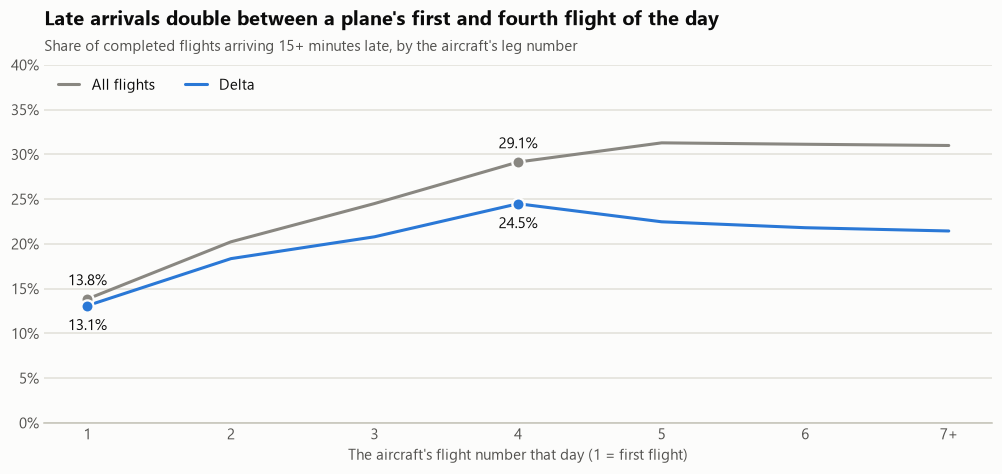

In [6]:
x = list(range(len(by_leg)))
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(x, by_leg["all_flights"], color=ps.MUTED, label="All flights", zorder=2)
ax.plot(x, by_leg["delta"], color=ps.BLUE, label="Delta", zorder=3)
for column, color in [("all_flights", ps.MUTED), ("delta", ps.BLUE)]:
    for i in (0, 3):
        ax.plot(i, by_leg[column].iloc[i], marker="o", markersize=8, color=color,
                markeredgecolor=ps.SURFACE, markeredgewidth=1.5, zorder=4)
        ax.annotate(f"{by_leg[column].iloc[i]:.1f}%", (i, by_leg[column].iloc[i]),
                    xytext=(0, 9 if column == "all_flights" else -16), textcoords="offset points",
                    ha="center", color=ps.INK)
ax.set_xticks(x, by_leg.index)
ax.set_xlabel("The aircraft's flight number that day (1 = first flight)")
ax.set_ylim(0, 40)
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.legend(loc="upper left", ncols=2, handlelength=1.4)
ps.title(ax, "Late arrivals double between a plane's first and fourth flight of the day",
         "Share of completed flights arriving 15+ minutes late, by the aircraft's leg number")
ps.save(fig, "late_rate_by_leg_number")
plt.show()

In [7]:
bins = [29, 44, 59, 89, 179, 599, 1440]
labels = ["30–44 min", "45–59 min", "60–89 min", "90 min – 3 hours", "3–10 hours", "10+ hours (overnight)"]
turnaround = pd.cut(features["turnaround_minutes"], bins, labels=labels)
by_turnaround = pd.DataFrame({
    "late_pct": late_pct(features, turnaround),
    "flights": turnaround.value_counts().reindex(labels),
})
by_turnaround.round(1)

,late_pct,flights
turnaround_minutes,,
30–44 min,28.0,1257306
45–59 min,25.7,1572333
60–89 min,24.1,1718011
90 min – 3 hours,21.5,527929
3–10 hours,13.9,1083179
10+ hours (overnight),18.1,737226


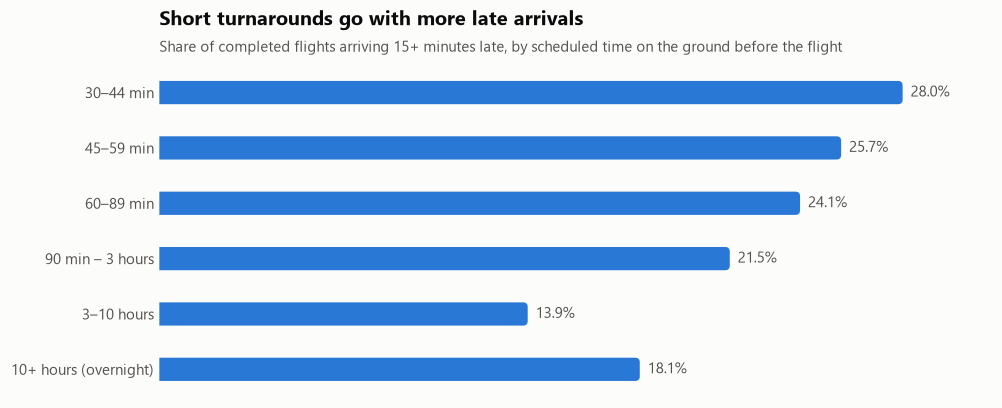

In [8]:
positions = list(range(len(by_turnaround)))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.set_xlim(0, by_turnaround["late_pct"].max() * 1.12)
ax.set_ylim(len(by_turnaround) - 0.5, -0.5)
ax.set_yticks(positions, by_turnaround.index)
ax.set_xticks([])
ax.grid(False)
ax.spines["bottom"].set_visible(False)
ps.title(ax, "Short turnarounds go with more late arrivals",
         "Share of completed flights arriving 15+ minutes late, by scheduled time on the ground before the flight")
ps.barh_rounded(ax, positions, by_turnaround["late_pct"].tolist(), ps.BLUE, height=0.42)
for pos, value in zip(positions, by_turnaround["late_pct"]):
    ax.text(value + 0.3, pos, f"{value:.1f}%", va="center", ha="left", color=ps.INK_2)
ps.save(fig, "late_rate_by_turnaround")
plt.show()

## 6. Holidays and crowding

In [9]:
holiday = pd.cut(features["days_from_holiday"], [-1, 0, 3, 7, 14],
                 labels=["On a federal holiday", "1–3 days from one", "4–7 days", "8+ days"])
crowding = pd.qcut(features["origin_departures_that_hour"], 4)
pd.concat({
    "Days from a federal holiday": late_pct(features, holiday).round(1),
    "Departures scheduled at the origin in the same hour": late_pct(features, crowding).round(1),
}).rename("late_%").to_frame()

late_%
Days from a federal holiday                        On a federal holiday    24.0
                                                   1–3 days from one       24.5
                                                   4–7 days                22.5
                                                   8+ days                 22.3
Departures scheduled at the origin in the same ... (0.999, 7.0]            20.4
                                                   (7.0, 19.0]             21.9
                                                   (19.0, 34.0]            24.0
                                                   (34.0, 108.0]           24.8

## 7. Aircraft type and age (FAA registry)

The FAA publishes a free registry of every U.S. aircraft. `src/aircraft.py` matches each tail number in the flight data to its registry record and keeps two facts: the **model family** (737-800, A321neo, E175, ...) and the **year built**. The registry also lists owners' names and addresses; those columns are never read.

Two reporting quirks had to be handled to get the match rate up: Allegiant leaves the leading "N" off its tail numbers, and for a few months Hawaiian's aircraft appear under Alaska with the wrong ending.

In [10]:
from aircraft import load_aircraft

aircraft = load_aircraft()
found = aircraft["registry_source"] != "not found"
print(f"Aircraft in the flight data: {len(aircraft):,}")
print(f"Matched to the FAA registry: {found.mean():.1%} of aircraft, "
      f"{aircraft.loc[found, 'flights'].sum() / aircraft['flights'].sum():.2%} of flights")

delta_fleet = (
    aircraft[aircraft["carrier"] == "DL"].groupby("aircraft_family")
    .agg(aircraft=("tail_number", "size"), flights=("flights", "sum"), typical_year_built=("year_built", "median"))
    .sort_values("flights", ascending=False)
)
delta_fleet["typical_year_built"] = delta_fleet["typical_year_built"].astype(int)
delta_fleet.head(10)

Aircraft in the flight data: 6,342
Matched to the FAA registry: 99.7% of aircraft, 99.99% of flights


,aircraft,flights,typical_year_built
aircraft_family,,,
737-900ER,163,207245,2016
A321,127,174795,2018
717,80,145368,2001
737-800,77,86537,2000
A321neo,101,81666,2024
A319,57,72138,2002
757-200,75,66821,1999
A320,49,62819,1998
A220-100,45,55420,2019


Does an older aircraft arrive late more often?

In [11]:
age_labels = ["0–4", "5–9", "10–14", "15–19", "20–24", "25+"]
age = pd.cut(features["aircraft_age_years"], [-1, 4, 9, 14, 19, 24, 60], labels=age_labels)
by_age = pd.DataFrame({
    "all_flights": late_pct(features, age),
    "delta": late_pct(features[is_delta], age[is_delta]),
    "flights": age.value_counts().reindex(age_labels),
    "delta_flights": age[is_delta].value_counts().reindex(age_labels),
})
by_age.round(1)

,all_flights,delta,flights,delta_flights
aircraft_age_years,,,,
0–4,23.2,20.9,1348164,132293
5–9,21.1,18.9,1380613,293297
10–14,23.1,17.1,1334095,133289
15–19,23.6,16.7,821971,5877
20–24,23.2,18.0,1167652,161167
25+,22.7,19.2,843489,292791


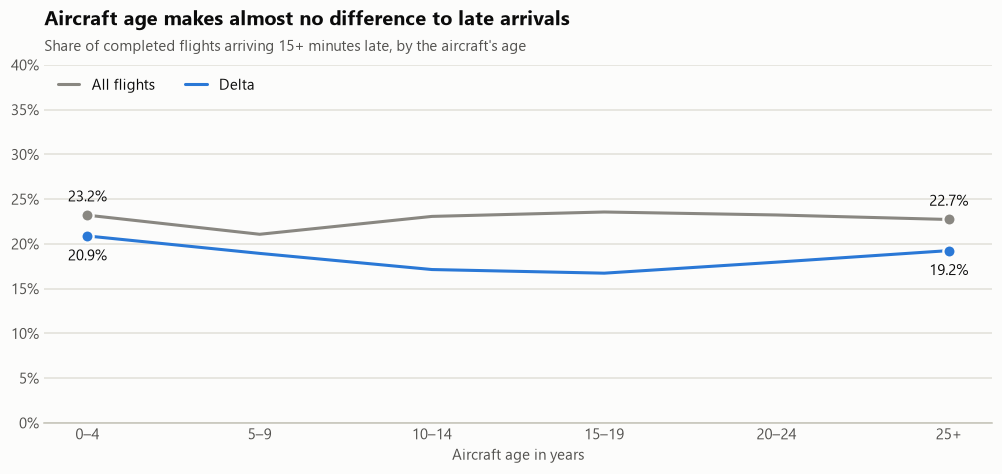

In [12]:
x = list(range(len(by_age)))
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(x, by_age["all_flights"], color=ps.MUTED, label="All flights", zorder=2)
ax.plot(x, by_age["delta"], color=ps.BLUE, label="Delta", zorder=3)
for column, color, offset in [("all_flights", ps.MUTED, 9), ("delta", ps.BLUE, -16)]:
    for i in (0, len(by_age) - 1):
        ax.plot(i, by_age[column].iloc[i], marker="o", markersize=8, color=color,
                markeredgecolor=ps.SURFACE, markeredgewidth=1.5, zorder=4)
        ax.annotate(f"{by_age[column].iloc[i]:.1f}%", (i, by_age[column].iloc[i]),
                    xytext=(0, offset), textcoords="offset points", ha="center", color=ps.INK)
ax.set_xticks(x, by_age.index)
ax.set_xlabel("Aircraft age in years")
ax.set_ylim(0, 40)
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.legend(loc="upper left", ncols=2, handlelength=1.4)
ps.title(ax, "Aircraft age makes almost no difference to late arrivals",
         "Share of completed flights arriving 15+ minutes late, by the aircraft's age")
ps.save(fig, "late_rate_by_aircraft_age")
plt.show()

The line is nearly flat. An old aircraft is about as punctual as a new one, for Delta and for all airlines. This is a simple comparison, and age is mixed up with airline and route, so the model gets the final say. It is still a useful finding: **when and how a plane is scheduled matters far more than how old it is.**

## What we learned

1. **There are 20 features,** with no missing values and no outcome columns. 13 come from the schedule alone. 7 depend on which aircraft flies the flight (rotation and aircraft details).
2. **The rotation idea holds up.** 13.8% of flights are late when it is the plane's first flight of the day, and 29.1% when it is the fourth. Delays pile up as the day goes on.
3. **Turnaround time matters.** With 30–44 minutes on the ground, 28.0% of flights arrive late. With 3–10 hours, 13.9% do.
4. **A leakage trap was found and closed.** 5.0% of flights were flown by an aircraft swapped in on the day, and 57.1% of those arrived late. Their rotation features now hold the flight's usual values, so the model cannot spot them.
5. **Aircraft age makes almost no difference.** Late rates stay between 21% and 24% from brand-new aircraft to those over 25 years old. The schedule matters far more than the plane's age.
6. **Holidays and crowding have smaller effects.** Flights on or near a federal holiday are late about 24% of the time, compared with about 22% otherwise. The busiest airport hours run about 4 points worse than the quietest.

## Next

**Notebook 03:** a baseline and a LightGBM model, split by date. The model is scored twice, with all 20 features and with the 13 schedule-only features, so the gain from the aircraft features is clear and the conservative result is on record.

Charts from this notebook are saved in `reports/figures/`.